<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/predicir_productividad_acad%C3%A9mica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FUENTE DE LOS DATOS**

https://www.kaggle.com/competitions/student-performance-prediction-machine-learning-challenge/data?utm_source=chatgpt.com

# **IMPORTACIÓN DE LIBRERÍAS**

In [121]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split, cross_validate, KFold
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# **CARGA DEL DATASET**

In [123]:
"""Carga los conjuntos de datos de entrenamiento y prueba.

   Returns:
       tuple[pd.DataFrame, pd.DataFrame]: DataFrame de train y DataFrame de test.
   """
def cargaDataset(train_path:str, test_path: str) -> tuple[pd.DataFrame, pd.DataFrame]:
   df_train = pd.read_csv(train_path)
   df_test = pd.read_csv('test.csv')
   return df_train, df_test

train_path = "train.csv"
test_path = "test.csv"
#df, df_test = cargaDataset(train_path, test_path)


# **ANÁLISIS INICIAL**

In [124]:
#df.sample(10)

In [125]:
#display(df.info())
#display(df.describe())

In [126]:
# Verificar valores nulos en el dataset

def verificar_ausencia_valores(df:pd.DataFrame) ->None:
   valores_faltantes = df.isnull().sum()
   if (valores_faltantes > 0).any():
       print("=== VALORES NULOS POR COLUMNA ===")
       display(valores_faltantes[valores_faltantes > 0])
   else:
       print("No hay valores faltantes")

   valores_duplicados = df.duplicated().sum()
   if valores_duplicados != 0:
       print("\n=== REGISTROS DUPLICADOS ===")
       print(f"Cantidad de registros completamente duplicados: {valores_duplicados}")
   else:
       print("No hay registros duplicados")

# Llamada a la función
#verificar_ausencia_valores(df)


# **CAMBIO DEL NOMBRE DE LOS PREDICTORES DEL DATASET**

In [97]:
"""Traduce el nombre de las columnas de un DataFrame al español.
    Args:
        df_dataset (pd.DataFrame): El DataFrame original con nombres en inglés.
    Returns:
        pd.DataFrame: Un nuevo DataFrame con las columnas traducidas al español.
"""
traduccion = {
        'id': 'id',
        'student_id': 'id_estudiante',
        'age': 'edad',
        'gender': 'genero',
        'study_hours_per_day': 'horas_estudio_por_dia',
        'sleep_hours': 'horas_sueno',
        'phone_usage_hours': 'horas_uso_telefono',
        'social_media_hours': 'horas_redes_sociales',
        'youtube_hours': 'horas_youtube',
        'gaming_hours': 'horas_videojuegos',
        'breaks_per_day': 'descansos_por_dia',
        'coffee_intake_mg': 'consumo_cafe_mg',
        'exercise_minutes': 'minutos_ejercicio',
        'assignments_completed': 'tareas_completadas',
        'attendance_percentage': 'porcentaje_asistencia',
        'stress_level': 'nivel_estres',
        'focus_score': 'puntaje_enfoque',
        'final_grade': 'calificacion_final',
        'productivity_score': 'puntaje_productividad'
    }

def traducir_columnas(df_dataset: pd.DataFrame, diccionario: dict) -> pd.DataFrame:
    return df_dataset.rename(columns=diccionario)

#df = traducir_columnas(df, traduccion)
#df_test = traducir_columnas(df_test, traduccion)

#print("Columnas del conjunto de entrenamiento:", df.columns.tolist())
#print("Columnas del dataset de prueba", df.columns.tolist())

Columnas del conjunto de entrenamiento: ['id', 'id_estudiante', 'edad', 'genero', 'horas_estudio_por_dia', 'horas_sueno', 'horas_uso_telefono', 'horas_redes_sociales', 'horas_youtube', 'horas_videojuegos', 'descansos_por_dia', 'consumo_cafe_mg', 'minutos_ejercicio', 'tareas_completadas', 'porcentaje_asistencia', 'nivel_estres', 'puntaje_enfoque', 'calificacion_final', 'puntaje_productividad']
Columnas del dataset de prueba ['id', 'id_estudiante', 'edad', 'genero', 'horas_estudio_por_dia', 'horas_sueno', 'horas_uso_telefono', 'horas_redes_sociales', 'horas_youtube', 'horas_videojuegos', 'descansos_por_dia', 'consumo_cafe_mg', 'minutos_ejercicio', 'tareas_completadas', 'porcentaje_asistencia', 'nivel_estres', 'puntaje_enfoque', 'calificacion_final', 'puntaje_productividad']


# **SEPARACIÓN DE LOS DATOS EN TRAIN Y  TEST**

### División de Datos para Validación Local

Vamos a separar nuestro conjunto **train.csv** en datos de entrenamiento **train** y de validación **val** para poder evaluar el rendimiento de nuestro modelo de forma local.

In [127]:
# Obtenemos las columnas del dataset y excluimos caracteriscas que no aporta informacion junto a la variable objetivo

def dividir_datos(df:pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
   features = [col for col in df.columns if col not in ['id', 'id_estudiante', 'puntaje_productividad']]
   target = 'puntaje_productividad'
   X = df[features]
   y = df[target]
   X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
   return X_train, X_test, y_train, y_test

#X_train, X_test, y_train, y_test= dividir_datos(df)
#print(f"Dimensiones de X_train (Entrenamiento):  {X_train.shape}")
#print(f"Dimensiones de X_val (Validación local): {X_test.shape}")


### **Visualización de Correlaciones (Mapa de Calor)**

In [134]:
"""
    Genera y muestra un mapa de calor de las correlaciones del dataset.
    Args:
        df_features (pd.DataFrame): DataFrame con las variables predictoras (ej. X_train).
        target_series (pd.Series, opcional): Serie con la variable objetivo a incluir en el análisis.
"""
def graficar_mapa_calor(X_train: pd.DataFrame, y_train: pd.Series = None) -> None:
    if y_train is not None:
        df_analisis = X_train.copy()
        df_analisis[y_train.name] = y_train
    else:
        df_analisis = X_train.copy()

    # Seleccionamos únicamente las columnas numéricas para la correlación
    df_numerico = df_analisis.select_dtypes(include=['int64', 'float64'])

    # Calculamos la matriz de correlación
    corr_matrix = df_numerico.corr()

    # Configuramos el lienzo de matplotlib
    plt.figure(figsize=(14, 10))

    # Dibujamos el mapa de calor
    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        linewidths=0.5,
        square=True
    )

    plt.title("Mapa de Calor de Correlaciones (Conjunto de Entrenamiento)", fontsize=16)
    plt.tight_layout()
    plt.show()


# Ejecutamos la función con el conjunto de entrenamiento (X_train) junto a su variable objetivo (y_train)
#graficar_mapa_calor(X_train, y_train)


### **Comparativa de Correlaciones (Pearson vs. Spearman)**

In [100]:
"""
   Calcula la información mutua para todas las características, codificando
   temporalmente las columnas categóricas como 'genero', y devuelve los resultados como Serie.
"""
def calcular_informacion_mutua(X_train: pd.DataFrame, y_train: pd.Series) -> pd.Series:
    X_temp = X_train.copy()

    for col in X_temp.select_dtypes(include=['object', 'category']).columns:
        X_temp[col] = X_temp[col].astype('category').cat.codes

    mi_scores = mutual_info_regression(X_temp, y_train, random_state=42)
    return pd.Series(mi_scores, index=X_train.columns)

In [128]:
def mostrar_tabla_correlaciones_completas(X_train: pd.DataFrame, y_train: pd.Series) -> None:
    df_temp = X_train.select_dtypes(include=['int64', 'float64']).copy()
    df_temp[y_train.name] = y_train

    corr_pearson = df_temp.corr(method='pearson')[y_train.name].drop(y_train.name)
    corr_spearman = df_temp.corr(method='spearman')[y_train.name].drop(y_train.name)

    info_mutua = calcular_informacion_mutua(X_train, y_train)


    df_corr = pd.DataFrame({
        'Pearson': corr_pearson,
        'Spearman': corr_spearman,
        'Informacion_Mutua': info_mutua
    }).reset_index()

    df_corr.rename(columns={'index': 'Variable'}, inplace=True)
    df_corr = df_corr.sort_values(by='Informacion_Mutua', ascending=False).reset_index(drop=True)
    print(f"Tabla Comparativa de Relaciones con {y_train.name}")
    display(df_corr)


#mostrar_tabla_correlaciones_completas(X_train, y_train)

### **Visualización de Distribuciones de las Variables Numéricas**

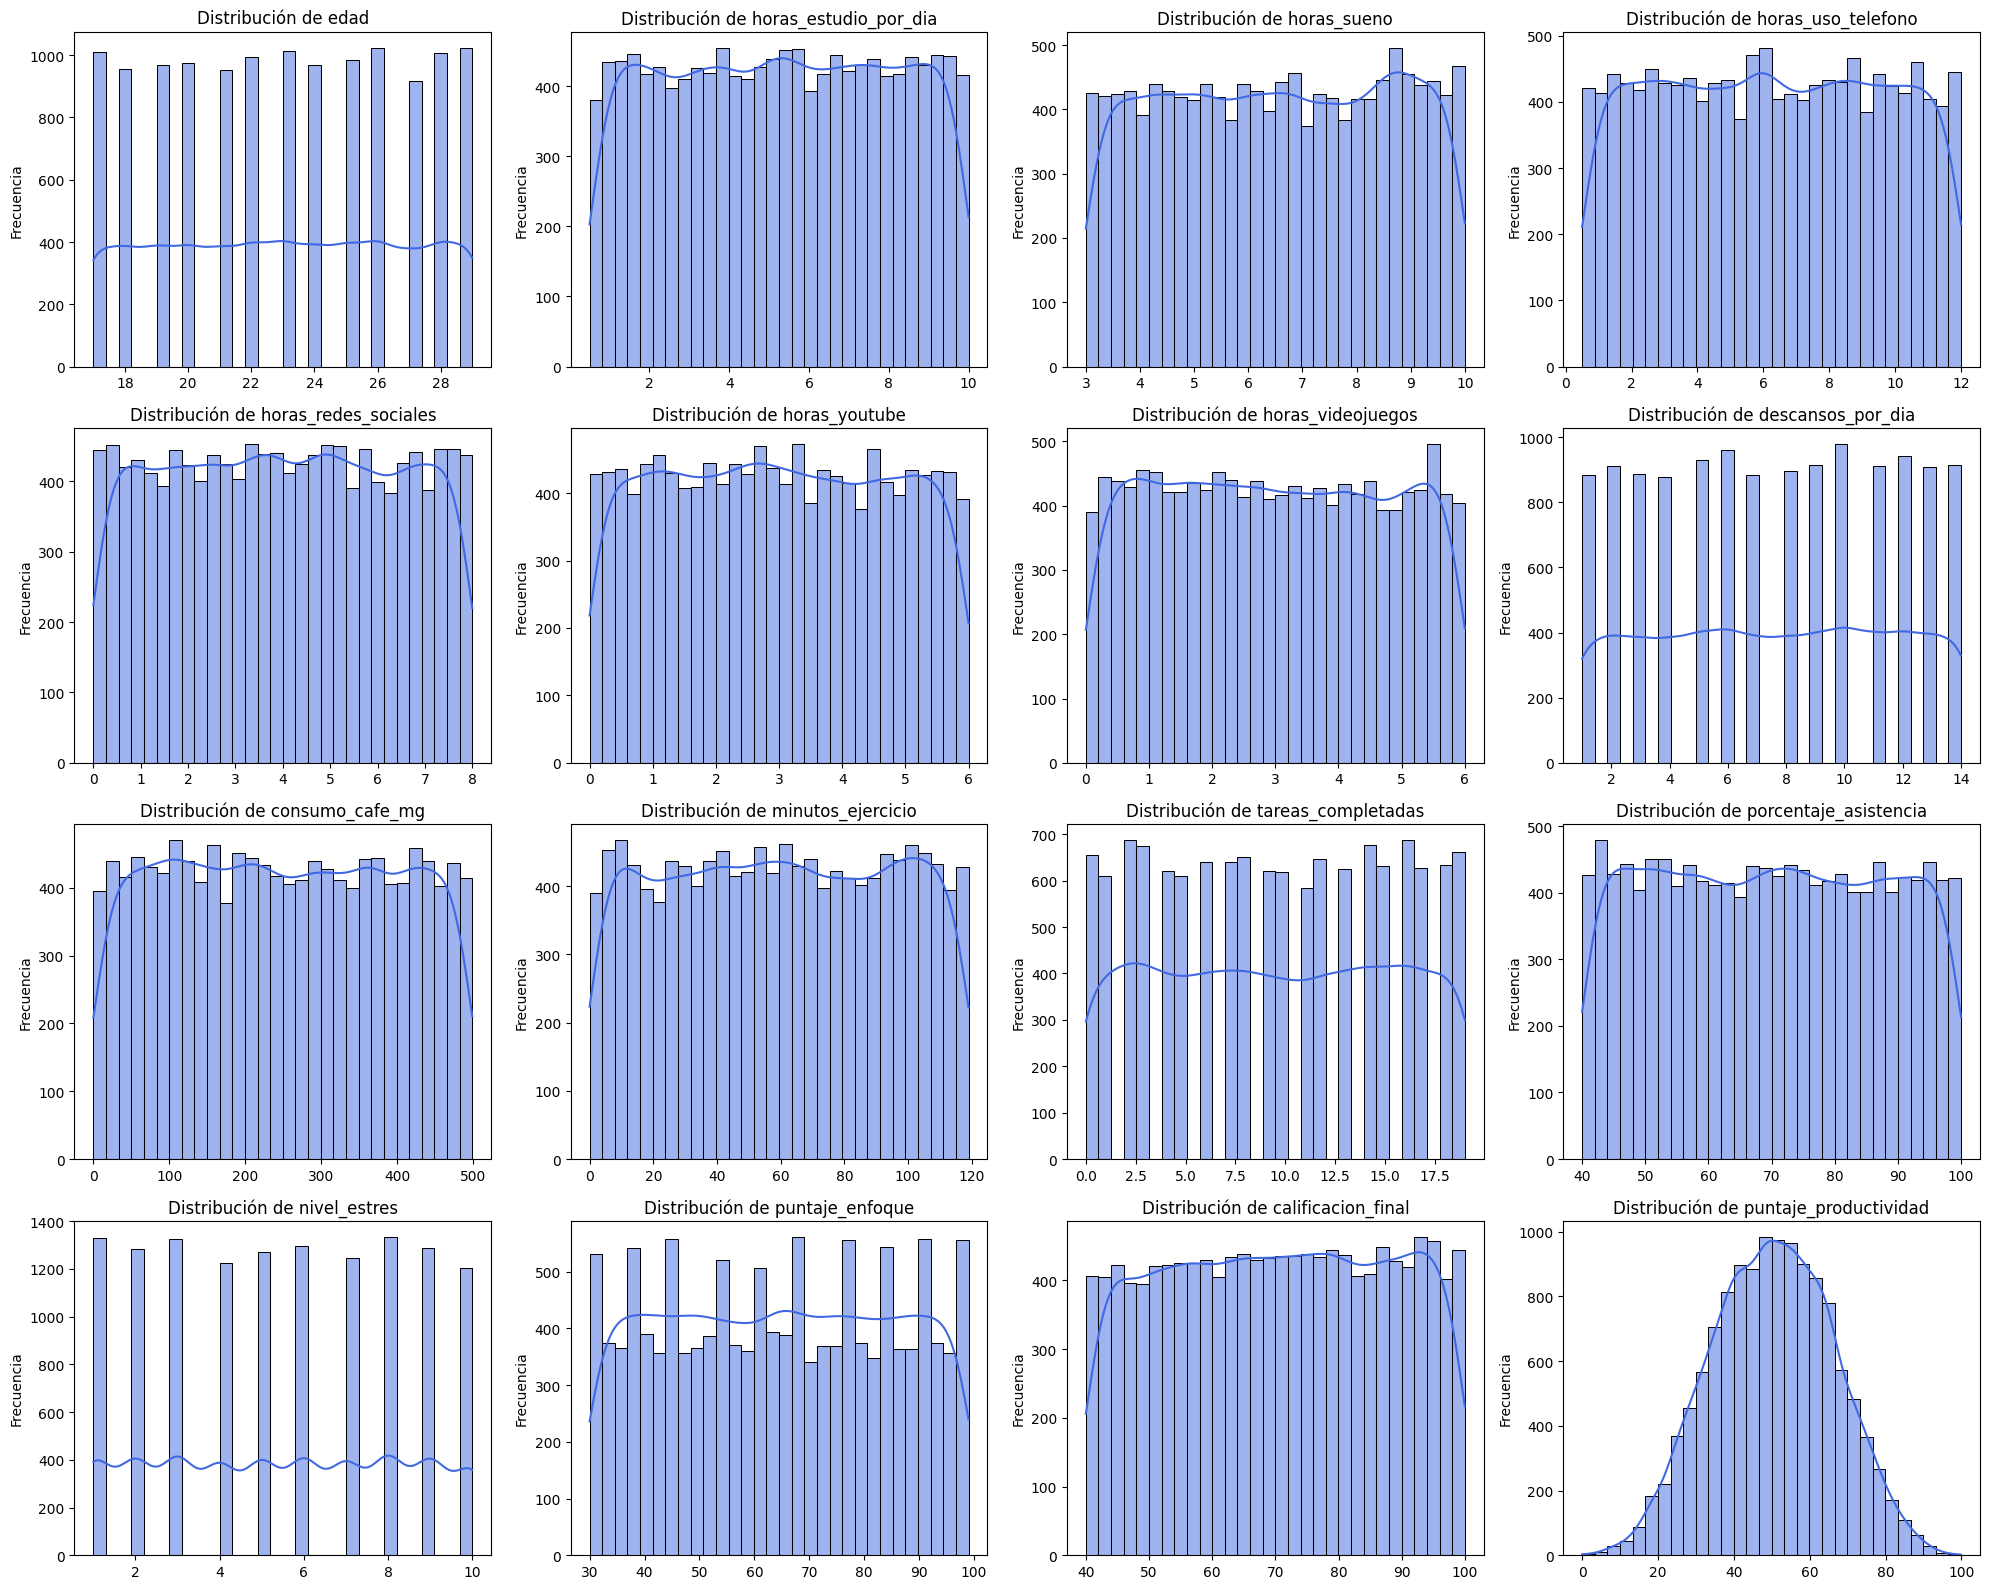

In [102]:
import math

def graficar_distribucion_variables(X_train: pd.DataFrame, y_train: pd.Series) -> None:
    """Grafica la distribución de todas las variables numéricas de X_train y la variable objetivo y_train."""
    # Unimos las características numéricas y el target
    df_temp = X_train.select_dtypes(include=['int64', 'float64']).copy()
    df_temp[y_train.name] = y_train

    columnas_numericas = df_temp.columns.tolist()
    num_cols = len(columnas_numericas)

    # Calculamos una cuadrícula rectangular óptima para los subplots
    grid_cols = 4
    grid_rows = math.ceil(num_cols / grid_cols)

    plt.figure(figsize=(20, 4 * grid_rows))

    for i, col in enumerate(columnas_numericas, 1):
        plt.subplot(grid_rows, grid_cols, i)
        # Usamos histplot para ver la distribución y la curva de densidad (KDE)
        sns.histplot(df_temp[col], kde=True, color='royalblue', bins=30)
        plt.title(f'Distribución de {col}', fontsize=12)
        plt.xlabel('')
        plt.ylabel('Frecuencia')

    plt.tight_layout()
    plt.show()

# Ejecutamos la función
#graficar_distribucion_variables(X_train, y_train)

In [66]:
#X_train.describe()

,edad,horas_estudio_por_dia,horas_sueno,horas_uso_telefono,horas_redes_sociales,horas_youtube,horas_videojuegos,descansos_por_dia,consumo_cafe_mg,minutos_ejercicio,tareas_completadas,porcentaje_asistencia,nivel_estres,puntaje_enfoque,calificacion_final
count,12800.000000,12800.000000,12800.00000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000,12800.000000
mean,23.023672,5.274297,6.53512,6.244887,3.994556,2.982699,2.985300,7.546953,248.954844,59.627031,9.508281,69.782534,5.464297,64.524375,70.342755
std,3.752644,2.738170,2.03639,3.318087,2.315936,1.728263,1.733383,4.017111,143.915987,34.598036,5.801123,17.403874,2.872008,20.221982,17.250460
min,17.000000,0.500000,3.00000,0.500000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,40.000000,1.000000,30.000000,40.000000
25%,20.000000,2.920000,4.77000,3.360000,2.000000,1.480000,1.480000,4.000000,124.000000,30.000000,4.000000,54.567500,3.000000,47.000000,55.610000
50%,23.000000,5.290000,6.54000,6.210000,3.980000,2.960000,2.960000,8.000000,247.000000,60.000000,9.000000,69.765000,5.000000,65.000000,70.505000
75%,26.000000,7.640000,8.35000,9.110000,5.970000,4.480000,4.490000,11.000000,372.000000,90.000000,15.000000,84.912500,8.000000,82.000000,85.342500
max,29.000000,10.000000,10.00000,12.000000,8.000000,6.000000,6.000000,14.000000,499.000000,119.000000,19.000000,99.990000,10.000000,99.000000,99.990000


## **Conclusiones del análisis de variables**

Evalué la relación de cada predictor con puntaje_productividad usando Pearson, Spearman e información mutua. Los tres métodos coinciden en los resultados.

**Variables que conservo:** horas_estudio_por_dia, puntaje_enfoque, horas_sueno, horas_uso_telefono, nivel_estres y porcentaje_asistencia. La más importante es horas_estudio_por_dia (r = 0.73).

**Variables que elimino:** edad, genero, consumo_cafe_mg, tareas_completadas, horas_redes_sociales, horas_youtube, horas_videojuegos, descansos_por_dia, minutos_ejercicio y calificacion_final.

**Por qué las elimino:**

- Su correlación es prácticamente nula (|r| < 0.02) y su información mutua es cero o despreciable, así que descarto relaciones lineales, monótonas y no lineales.
- Como tres métodos distintos llegan a lo mismo, considero que el resultado es confiable.
- Mantenerlas solo agregaría ruido y aumentaría el riesgo de sobreajuste sin mejorar las predicciones.

Además, como Pearson y Spearman dan valores casi iguales, concluyo que las relaciones son aproximadamente lineales, por lo que usaré una regresión lineal como modelo base.

In [129]:
def eliminar_variables(df_dataset: pd.DataFrame, columnas_eliminar: dict) -> pd.DataFrame:
    columnas = list(columnas_eliminar.keys())

    faltantes = [col for col in columnas if col not in df_dataset.columns]
    if faltantes:
        print(f"Advertencia: estas columnas no existen y se omiten: {faltantes}")

    return df_dataset.drop(columns=columnas, errors='ignore')


variables_irrelevantes = {
    "id": "Identificador único no aporta información",
    "id_estudiante": "Identificador del estudiante no aporta información",
    'edad': 'Correlación e información mutua nulas',
    'genero': 'Información mutua nula',
    'consumo_cafe_mg': 'Correlación e información mutua nulas',
    'tareas_completadas': 'Correlación e información mutua nulas',
    'horas_redes_sociales': 'Correlación e información mutua nulas',
    'horas_youtube': 'Correlación e información mutua nulas',
    'horas_videojuegos': 'Correlación e información mutua nulas',
    'descansos_por_dia': 'Correlación e información mutua nulas',
    'minutos_ejercicio': 'Correlación e información mutua nulas',
    'calificacion_final': 'Correlación e información mutua nulas',
}

#X_train_limpia = eliminar_variables(X_train, variables_irrelevantes)
#X_test_limpia = eliminar_variables(X_test, variables_irrelevantes)
#X_train_limpia = X_train
#X_test_limpia= X_test
#X_train_limpia = X_train_limpia.drop(columns="genero")
#X_test_limpia = X_test_limpia.drop(columns="genero")
#display(X_train_limpia.sample(10))


### **Escalamiento de Variables con StandardScaler**

In [131]:
from sklearn.preprocessing import StandardScaler

def escalar_datos(X_train: pd.DataFrame, X_test: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, StandardScaler]:
    """Escala los conjuntos de datos de entrenamiento y prueba usando StandardScaler.

    Args:
        X_train (pd.DataFrame): Conjunto de entrenamiento.
        X_test (pd.DataFrame): Conjunto de prueba/validación.

    Returns:
        tuple: (X_train_escalado, X_test_escalado, scaler)
    """
    scaler = StandardScaler()

    # Ajustamos con entrenamiento y transformamos ambos
    X_train_esc = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns=X_train.columns,
        index=X_train.index
    )
    X_test_esc = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns,
        index=X_test.index
    )

    return X_train_esc, X_test_esc, scaler

# Ejecución de la función con nuestros datos
#X_train_escalado, X_test_escalado, scaler_entrenado = escalar_datos(X_train_limpia, X_test_limpia)

# Mostramos las estadísticas descriptivas para verificar el resultado
#print("=== Estadísticas del conjunto de entrenamiento escalado ===")
#display(X_train_escalado.describe().round(4))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     16000 non-null  int64  
 1   student_id             16000 non-null  int64  
 2   age                    16000 non-null  int64  
 3   gender                 16000 non-null  object 
 4   study_hours_per_day    16000 non-null  float64
 5   sleep_hours            16000 non-null  float64
 6   phone_usage_hours      16000 non-null  float64
 7   social_media_hours     16000 non-null  float64
 8   youtube_hours          16000 non-null  float64
 9   gaming_hours           16000 non-null  float64
 10  breaks_per_day         16000 non-null  int64  
 11  coffee_intake_mg       16000 non-null  int64  
 12  exercise_minutes       16000 non-null  int64  
 13  assignments_completed  16000 non-null  int64  
 14  attendance_percentage  16000 non-null  float64
 15  st

None

,id,student_id,age,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,assignments_completed,attendance_percentage,stress_level,focus_score,final_grade,productivity_score
count,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,10006.506875,10007.506875,23.020937,5.254446,6.515254,6.258692,3.995989,2.985526,2.976373,7.539625,249.035250,59.832125,9.492313,69.894694,5.478813,64.430375,70.377071,50.146637
std,5790.786923,5790.786923,3.753283,2.743874,2.033761,3.305756,2.311722,1.731141,1.733127,4.017236,143.732208,34.676427,5.781352,17.408698,2.867785,20.226804,17.293340,16.095733
min,1.000000,2.000000,17.000000,0.500000,3.000000,0.500000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,40.000000,1.000000,30.000000,40.000000,0.000000
25%,4993.750000,4994.750000,20.000000,2.890000,4.760000,3.390000,2.000000,1.480000,1.477500,4.000000,124.000000,30.000000,4.000000,54.740000,3.000000,47.000000,55.617500,38.657500
50%,10020.500000,10021.500000,23.000000,5.250000,6.520000,6.230000,3.990000,2.970000,2.950000,8.000000,248.000000,60.000000,9.000000,69.865000,5.000000,65.000000,70.545000,50.220000
75%,15029.250000,15030.250000,26.000000,7.632500,8.320000,9.100000,5.970000,4.480000,4.490000,11.000000,372.000000,90.000000,15.000000,85.020000,8.000000,82.000000,85.480000,61.840000
max,19999.000000,20000.000000,29.000000,10.000000,10.000000,12.000000,8.000000,6.000000,6.000000,14.000000,499.000000,119.000000,19.000000,100.000000,10.000000,99.000000,99.990000,100.000000


No hay valores faltantes
No hay registros duplicados
Columnas del conjunto de entrenamiento: ['id', 'id_estudiante', 'edad', 'genero', 'horas_estudio_por_dia', 'horas_sueno', 'horas_uso_telefono', 'horas_redes_sociales', 'horas_youtube', 'horas_videojuegos', 'descansos_por_dia', 'consumo_cafe_mg', 'minutos_ejercicio', 'tareas_completadas', 'porcentaje_asistencia', 'nivel_estres', 'puntaje_enfoque', 'calificacion_final', 'puntaje_productividad']
Columnas del dataset de prueba ['id', 'id_estudiante', 'edad', 'genero', 'horas_estudio_por_dia', 'horas_sueno', 'horas_uso_telefono', 'horas_redes_sociales', 'horas_youtube', 'horas_videojuegos', 'descansos_por_dia', 'consumo_cafe_mg', 'minutos_ejercicio', 'tareas_completadas', 'porcentaje_asistencia', 'nivel_estres', 'puntaje_enfoque', 'calificacion_final', 'puntaje_productividad']
Dimensiones de X_train (Entrenamiento):  (12800, 16)
Dimensiones de X_val (Validación local): (3200, 16)


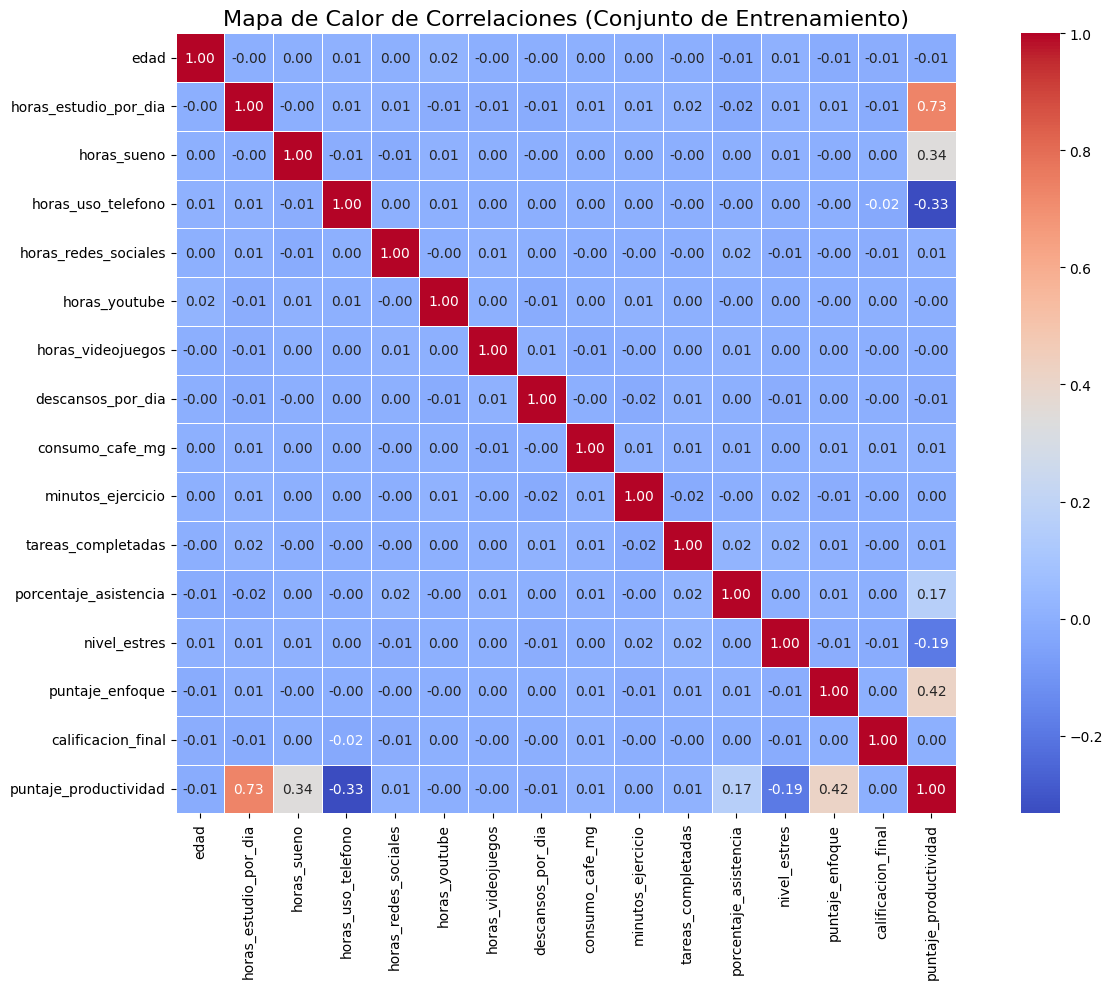

Tabla Comparativa de Relaciones con puntaje_productividad


,Variable,Pearson,Spearman,Informacion_Mutua
0,horas_estudio_por_dia,0.729812,0.736597,0.383025
1,puntaje_enfoque,0.416305,0.401436,0.101640
2,horas_sueno,0.340266,0.327444,0.070934
3,horas_uso_telefono,-0.332687,-0.318610,0.064655
4,nivel_estres,-0.188585,-0.177642,0.021909
5,porcentaje_asistencia,0.166646,0.158397,0.013250
6,horas_videojuegos,-0.001555,-0.001590,0.002985
7,consumo_cafe_mg,0.012683,0.011896,0.002791
8,horas_youtube,-0.004620,-0.005199,0.002301
9,descansos_por_dia,-0.006393,-0.004271,0.002291


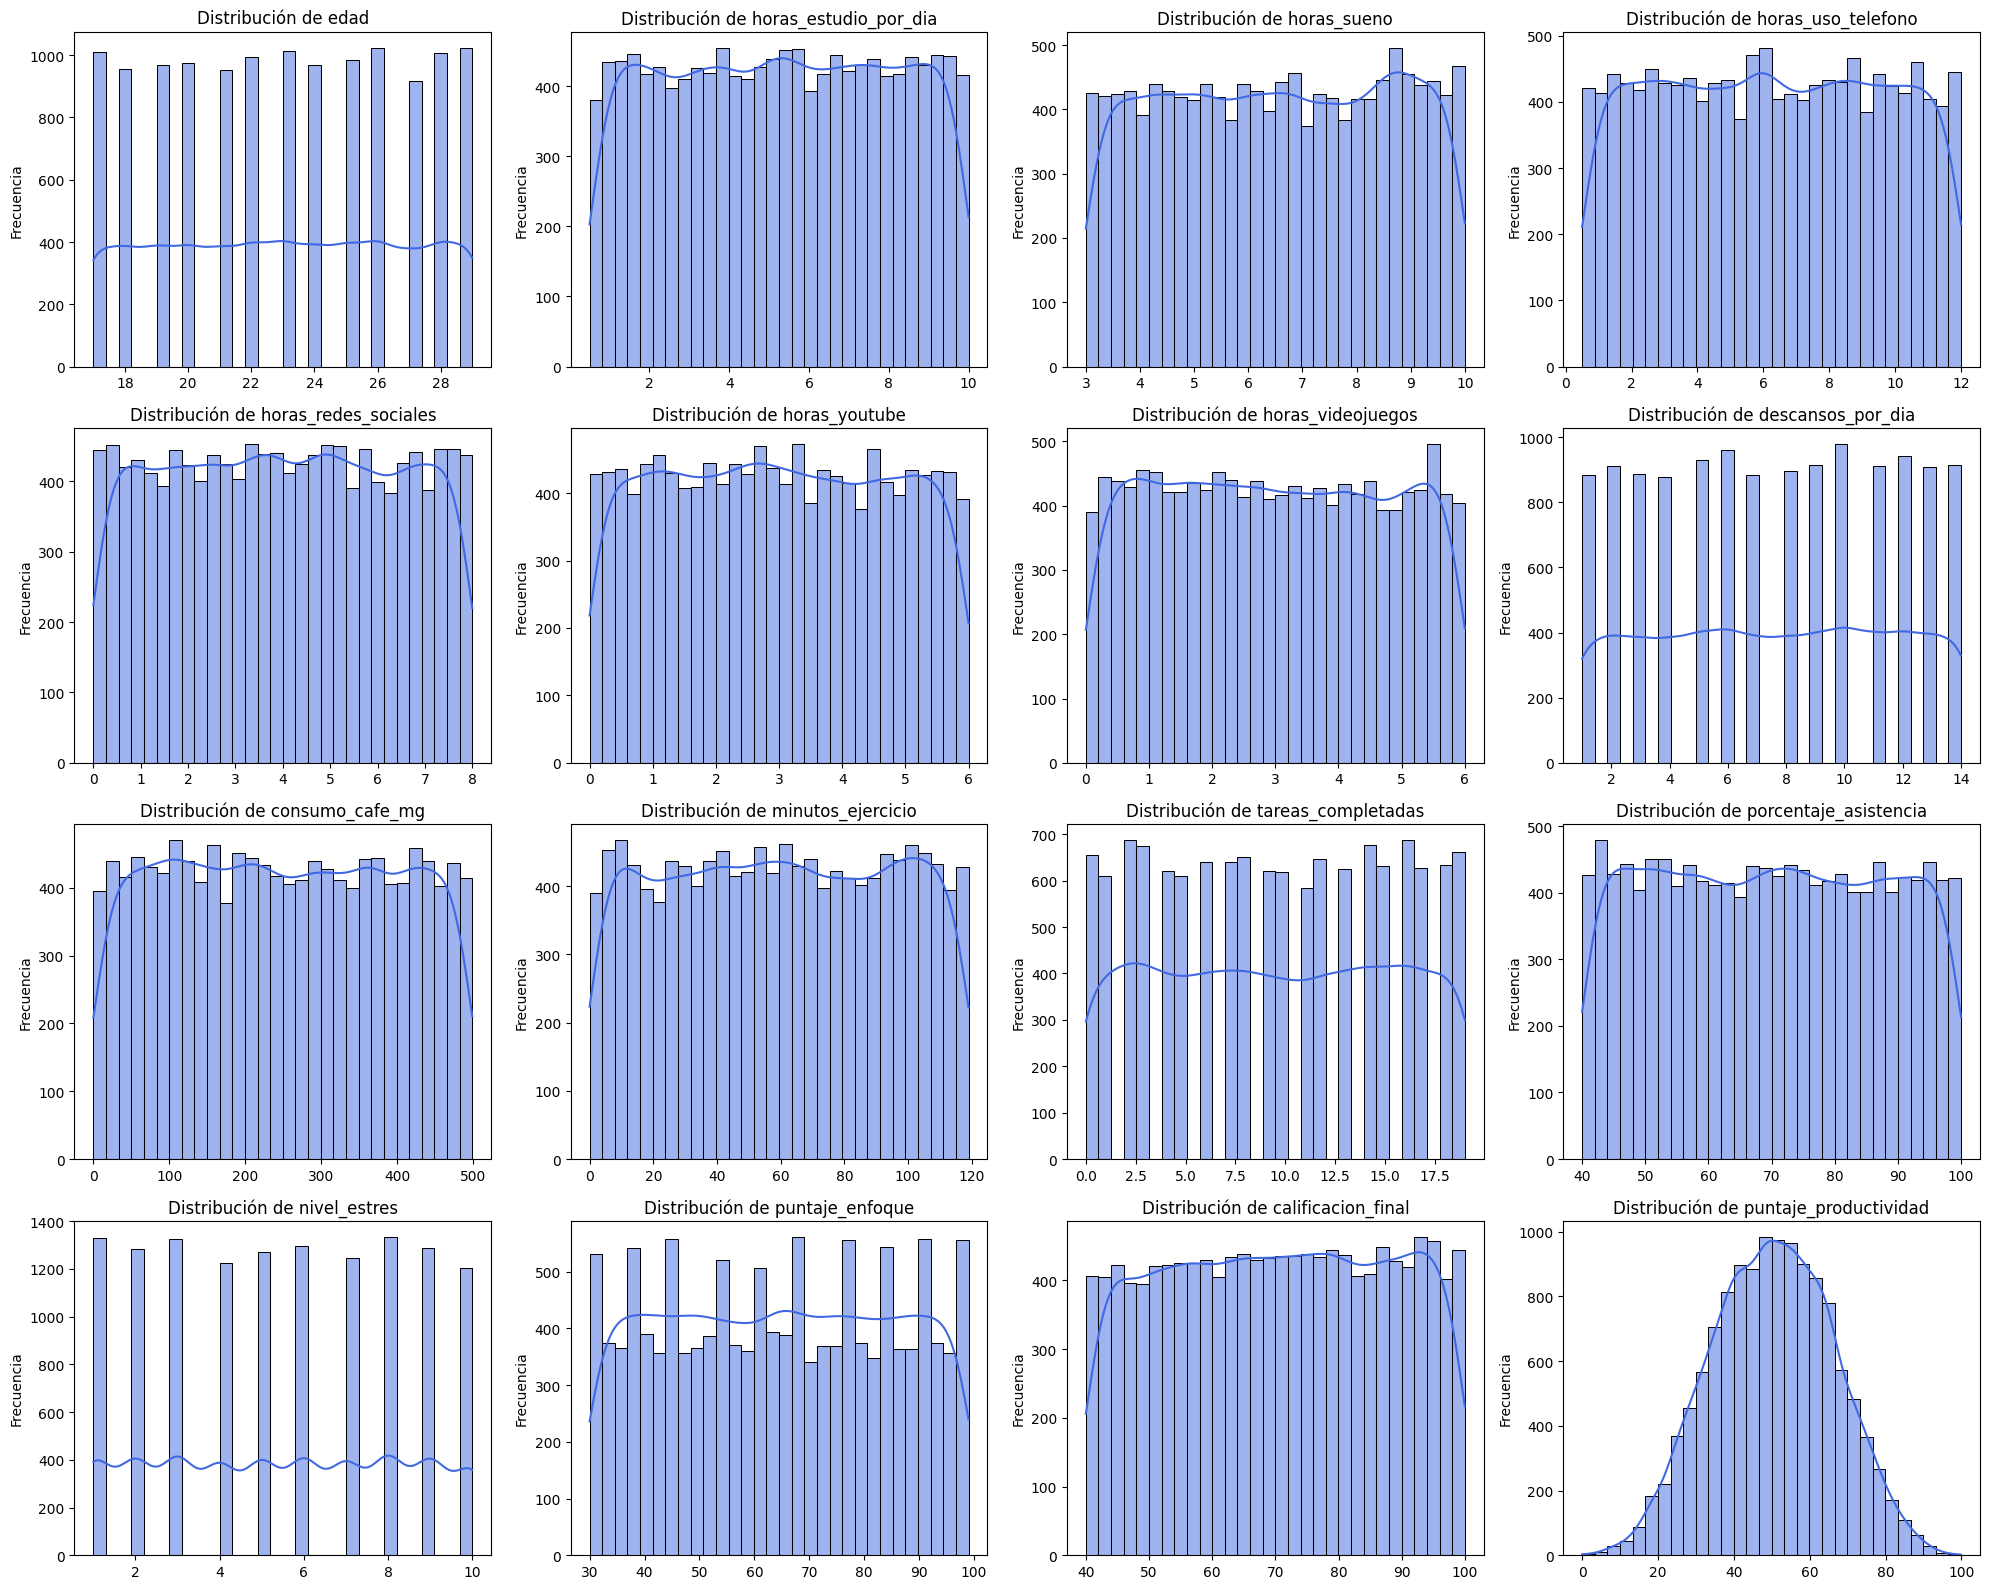

,edad,horas_estudio_por_dia,horas_sueno,horas_uso_telefono,horas_redes_sociales,horas_youtube,horas_videojuegos,descansos_por_dia,consumo_cafe_mg,minutos_ejercicio,tareas_completadas,porcentaje_asistencia,nivel_estres,puntaje_enfoque,calificacion_final
15218,17,0.70,9.28,7.96,2.81,0.19,5.41,3,59,40,3,94.35,10,97,78.64
6149,20,8.91,3.39,10.97,2.75,1.33,1.10,8,74,98,12,72.06,6,67,56.47
4530,22,2.58,8.67,4.71,0.85,1.76,3.71,1,368,88,9,75.84,10,71,74.59
3771,25,4.57,7.74,6.71,4.46,1.92,3.78,10,365,117,10,89.14,1,65,80.34
15215,24,7.39,5.23,7.81,4.34,5.97,1.68,10,433,26,8,81.96,9,99,91.28
10036,21,0.52,6.74,3.25,2.74,5.23,4.08,2,284,27,16,42.73,6,99,89.14
4378,29,9.11,4.27,6.56,0.57,1.52,2.68,12,474,66,15,41.80,10,96,74.28
9043,27,9.72,7.99,1.33,0.93,1.06,0.70,12,159,35,9,72.98,5,87,75.84
2632,23,2.98,7.96,10.07,5.23,5.86,1.60,9,291,7,14,53.78,10,63,93.89
8234,22,2.85,4.35,9.09,5.44,1.34,0.23,1,23,107,17,63.86,7,93,99.58


¿Cómo deseas entrenar el modelo?
  1. Entrenar con las variables seleccionadas
  2. Entrenar con todas las variables
Escribe el número de la opción: 2

Opción elegida: Entrenar con todas las variables

    TODAS LAS VARIABLES (17 variables)   
['edad', 'horas_estudio_por_dia', 'horas_sueno', 'horas_uso_telefono', 'horas_redes_sociales', 'horas_youtube', 'horas_videojuegos', 'descansos_por_dia', 'consumo_cafe_mg', 'minutos_ejercicio', 'tareas_completadas', 'porcentaje_asistencia', 'nivel_estres', 'puntaje_enfoque', 'calificacion_final', 'genero_Male', 'genero_Other'] 

    VALIDACIÓN CRUZADA (5 FOLDS)    


,Media,Desviación
MAE,0.0025,0.0
RMSE,0.0029,0.0
R2,1.0000,0.0



    MÉTRICAS    


,Entrenamiento,Test
MAE,0.0025,0.0025
MSE,0.0000,0.0000
RMSE,0.0029,0.0029
R2,1.0000,1.0000



    COEFICIENTES    


,Variable,Coeficiente
0,horas_estudio_por_dia,11.8185
1,puntaje_enfoque,6.5462
2,horas_sueno,5.4934
3,horas_uso_telefono,-5.3705
4,nivel_estres,-3.0990
5,porcentaje_asistencia,2.8169
6,horas_videojuegos,0.0000
7,descansos_por_dia,-0.0000
8,genero_Other,0.0000
9,calificacion_final,-0.0000


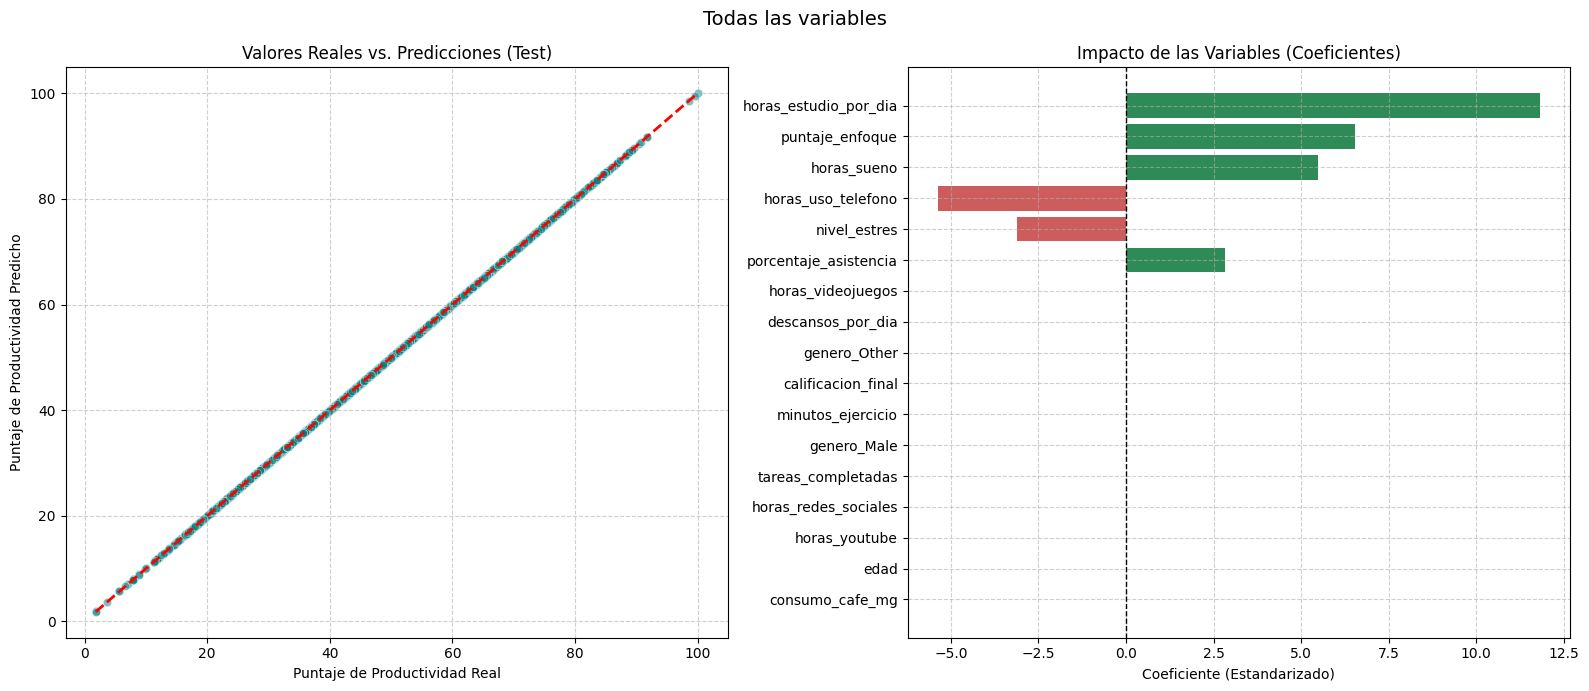

In [133]:
COLUMNAS_ID = ['id', 'id_estudiante']

VARIABLES_SELECCIONADAS = [
    'horas_estudio_por_dia',
    'puntaje_enfoque',
    'horas_sueno',
    'horas_uso_telefono',
    'nivel_estres',
    'porcentaje_asistencia'
]

OPCIONES = {
    '1': 'Entrenar con las variables seleccionadas',
    '2': 'Entrenar con todas las variables'
}


# ================= PREPARACIÓN =================
def preparar_datos(X_train: pd.DataFrame, X_test: pd.DataFrame,
                   variables: list = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    X_tr = X_train.drop(columns=COLUMNAS_ID, errors='ignore').copy()
    X_te = X_test.drop(columns=COLUMNAS_ID, errors='ignore').copy()

    if variables is not None:
        return X_tr[variables], X_te[variables]

    categoricas = X_tr.select_dtypes(include=['object', 'category']).columns.tolist()
    X_tr = pd.get_dummies(X_tr, columns=categoricas, drop_first=True, dtype=int)
    X_te = pd.get_dummies(X_te, columns=categoricas, drop_first=True, dtype=int)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)

    return X_tr, X_te

def crear_pipeline() -> Pipeline:
    return Pipeline([
        ('escalador', StandardScaler()),
        ('modelo', LinearRegression())
    ])


def validacion_cruzada(pipeline: Pipeline, X: pd.DataFrame, y: pd.Series,
                       n_splits: int = 5) -> pd.DataFrame:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    res = cross_validate(
        pipeline, X, y, cv=kfold,
        scoring={'MAE': 'neg_mean_absolute_error',
                 'RMSE': 'neg_root_mean_squared_error',
                 'R2': 'r2'}
    )
    mae, rmse, r2 = -res['test_MAE'], -res['test_RMSE'], res['test_R2']

    return pd.DataFrame({
        'Media': [mae.mean(), rmse.mean(), r2.mean()],
        'Desviación': [mae.std(), rmse.std(), r2.std()]
    }, index=['MAE', 'RMSE', 'R2']).round(4)


def calcular_metricas(y_real: pd.Series, y_pred: np.ndarray) -> dict:
    mse = mean_squared_error(y_real, y_pred)
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_real, y_pred)
    }


def obtener_coeficientes(pipeline: Pipeline, columnas: pd.Index) -> pd.DataFrame:
   return pd.DataFrame({
        'Variable': columnas,
        'Coeficiente': pipeline.named_steps['modelo'].coef_
    }).sort_values(by='Coeficiente', key=abs, ascending=False).reset_index(drop=True)


def graficar_resultados(y_real: pd.Series, y_pred: np.ndarray,
                        df_coef: pd.DataFrame, titulo: str = '') -> None:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle(titulo, fontsize=14)

    sns.scatterplot(x=y_real, y=y_pred, alpha=0.5, ax=axes[0], color='teal')
    axes[0].plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()], 'r--', lw=2)
    axes[0].set_title('Valores Reales vs. Predicciones (Test)')
    axes[0].set_xlabel('Puntaje de Productividad Real')
    axes[0].set_ylabel('Puntaje de Productividad Predicho')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    colores = ['seagreen' if c > 0 else 'indianred' for c in df_coef['Coeficiente']]
    axes[1].barh(df_coef['Variable'], df_coef['Coeficiente'], color=colores)
    axes[1].invert_yaxis()
    axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
    axes[1].set_title('Impacto de las Variables (Coeficientes)')
    axes[1].set_xlabel('Coeficiente (Estandarizado)')
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


# ================= FLUJO DE ENTRENAMIENTO =================
def entrenar_modelo(X_train: pd.DataFrame, X_test: pd.DataFrame,
                    y_train: pd.Series, y_test: pd.Series,
                    variables: list = None, nombre: str = 'Modelo',
                    graficar: bool = True) -> dict:

    X_tr, X_te = preparar_datos(X_train, X_test, variables)

    print(f"\n    {nombre.upper()} ({X_tr.shape[1]} variables)   ")
    print(X_tr.columns.tolist(), "\n")

    pipeline = crear_pipeline()

    metricas_cv = validacion_cruzada(pipeline, X_tr, y_train)
    print("    VALIDACIÓN CRUZADA (5 FOLDS)    ")
    display(metricas_cv)

    pipeline.fit(X_tr, y_train)
    y_pred_train = pipeline.predict(X_tr)
    y_pred_test = pipeline.predict(X_te)

    metricas = pd.DataFrame({
        'Entrenamiento': calcular_metricas(y_train, y_pred_train),
        'Test': calcular_metricas(y_test, y_pred_test)
    }).round(4)
    print("\n    MÉTRICAS    ")
    display(metricas)

    coeficientes = obtener_coeficientes(pipeline, X_tr.columns)
    print("\n    COEFICIENTES    ")
    display(coeficientes.round(4))

    if graficar:
        graficar_resultados(y_test, y_pred_test, coeficientes, titulo=nombre)

    return {
        'pipeline': pipeline,
        'metricas_cv': metricas_cv,
        'metricas': metricas,
        'coeficientes': coeficientes
    }


# ================= MENÚ =================
def elegir_opcion() -> str:
    print("¿Cómo deseas entrenar el modelo?")
    for clave, descripcion in OPCIONES.items():
        print(f"  {clave}. {descripcion}")

    opcion = input("Escribe el número de la opción: ").strip()
    while opcion not in OPCIONES:
        opcion = input("Opción no válida. Escribe 1 o 2: ").strip()
    return opcion


# ================= ORQUESTADOR =================
def main(X_train: pd.DataFrame, X_test: pd.DataFrame,
         y_train: pd.Series, y_test: pd.Series, opcion: str = None) -> dict:

    if opcion is None:
        opcion = elegir_opcion()

    print(f"\nOpción elegida: {OPCIONES[opcion]}")

    if opcion == '1':
        return entrenar_modelo(X_train, X_test, y_train, y_test,
                               variables=VARIABLES_SELECCIONADAS,
                               nombre='Variables seleccionadas')

    return entrenar_modelo(X_train, X_test, y_train, y_test,
                           variables=None,
                           nombre='Todas las variables')


if __name__ == "__main__":
    df, df_test = cargaDataset(train_path, test_path)
    df.sample(10)
    display(df.info())
    display(df.describe())
    verificar_ausencia_valores(df)
    df = traducir_columnas(df, traduccion)
    df_test = traducir_columnas(df_test, traduccion)
    print("Columnas del conjunto de entrenamiento:", df.columns.tolist())
    print("Columnas del dataset de prueba", df.columns.tolist())
    X_train, X_test, y_train, y_test= dividir_datos(df)
    print(f"Dimensiones de X_train (Entrenamiento):  {X_train.shape}")
    print(f"Dimensiones de X_val (Validación local): {X_test.shape}")
    graficar_mapa_calor(X_train, y_train)
    mostrar_tabla_correlaciones_completas(X_train, y_train)
    graficar_distribucion_variables(X_train, y_train)
    X_train.describe()
    X_train_limpia = X_train
    X_test_limpia= X_test
    X_train_limpia = X_train_limpia.drop(columns="genero")
    X_test_limpia = X_test_limpia.drop(columns="genero")
    display(X_train_limpia.sample(10))
    X_train_escalado, X_test_escalado, scaler_entrenado = escalar_datos(X_train_limpia, X_test_limpia)

    resultado = main(X_train, X_test, y_train, y_test)

## **Conclusiones de las distribuciones**

Observo que todas las variables predictoras tienen una distribución aproximadamente uniforme, mientras que puntaje_productividad tiene forma de campana, cercana a una normal. Esto se debe hecho de que el dataset es sintético y que la variable objetivo probablemente se construyó como una combinación lineal de unas pocas variables.

Las distribuciones no cambian mi decisión de eliminar las 10 variables irrelevantes, ya que su forma no compensa que no aportan información sobre la variable objetivo.

En las 6 variables que conservo no encuentro outliers, sesgos ni valores fuera de rango, así que no aplico transformaciones. Nivel_estres es discreta (valores enteros de 1 a 10), lo que no representa un problema para el modelo. Sí voy a escalar estas variables, porque tienen rangos distintos y eso afecta la interpretación de los coeficientes en una regresión lineal.

Entrené el modelo con todas las variables y obtuve el mismo desempeño que con las 6 seleccionadas. Además, el modelo asignó coeficientes de cero a las 10 variables que había identificado como irrelevantes. Esto confirma, de forma independiente a la correlación y la información mutua, que esas variables no aportan información, por lo que me quedo con el modelo de 6 variables por ser más simple e interpretable.

## Conclusión del ejercicio

Analicé un dataset de Kaggle para predecir la productividad de estudiantes a partir de 16 variables.

Con Pearson, Spearman e información mutua identifiqué que solo 6 variables influyen en la productividad: horas de estudio, enfoque, sueño, uso del teléfono, estrés y asistencia. Las otras 10 no tienen ninguna relación con el objetivo, y lo confirmé al entrenar con todas las variables, ya que el modelo les asignó coeficiente cero.

Entrené una regresión lineal con un Pipeline y validación cruzada, y obtuve un R² de 1.0 con un error de 0.0025, que coincide exactamente con el error de redondear a 2 decimales. Al desconfiar de un resultado tan perfecto. dado que el dataset es sintético: la productividad se generó con una fórmula lineal de esas 6 variables, y mi modelo la reconstruyó.

Con este ejercicio practiqué análisis exploratorio, selección de variables, pipelines, validación cruzada y organización del código en funciones. También aprendí a verificar los resultados en lugar de aceptarlos sin más. Como el dataset no tiene ruido, no sirve para comparar modelos más complejos, así que el siguiente paso es trabajar con datos reales.